In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

listings = pd.read_csv('../02_Data/processed/listings_clean.csv', low_memory=False)


In [4]:
# Room type comparison
rt_stats = listings.groupby('room_type').agg(
    listings=('id', 'count'),
    share_pct=('id', lambda s: round(len(s)/len(listings)*100, 1)),
    median_price=('price', 'median'),
    p25_price=('price', lambda s: s.quantile(0.25)),
    p75_price=('price', lambda s: s.quantile(0.75)),
    median_accommodates=('accommodates', 'median'),
    median_min_nights=('minimum_nights', 'median'),
    pct_superhost=('host_is_superhost', lambda s: round(s.mean()*100, 1))
).round(1)

display(rt_stats)

,listings,share_pct,median_price,p25_price,p75_price,median_accommodates,median_min_nights,pct_superhost
room_type,,,,,,,,
Entire home/apt,10844,70.9,221.5,128.0,316.0,4.0,2.0,30.4
Hotel room,68,0.4,196.1,171.6,263.4,2.0,1.0,29.4
Private room,4262,27.9,64.0,38.4,131.0,2.0,3.0,14.5
Shared room,119,0.8,46.0,40.0,63.0,1.0,1.0,10.9


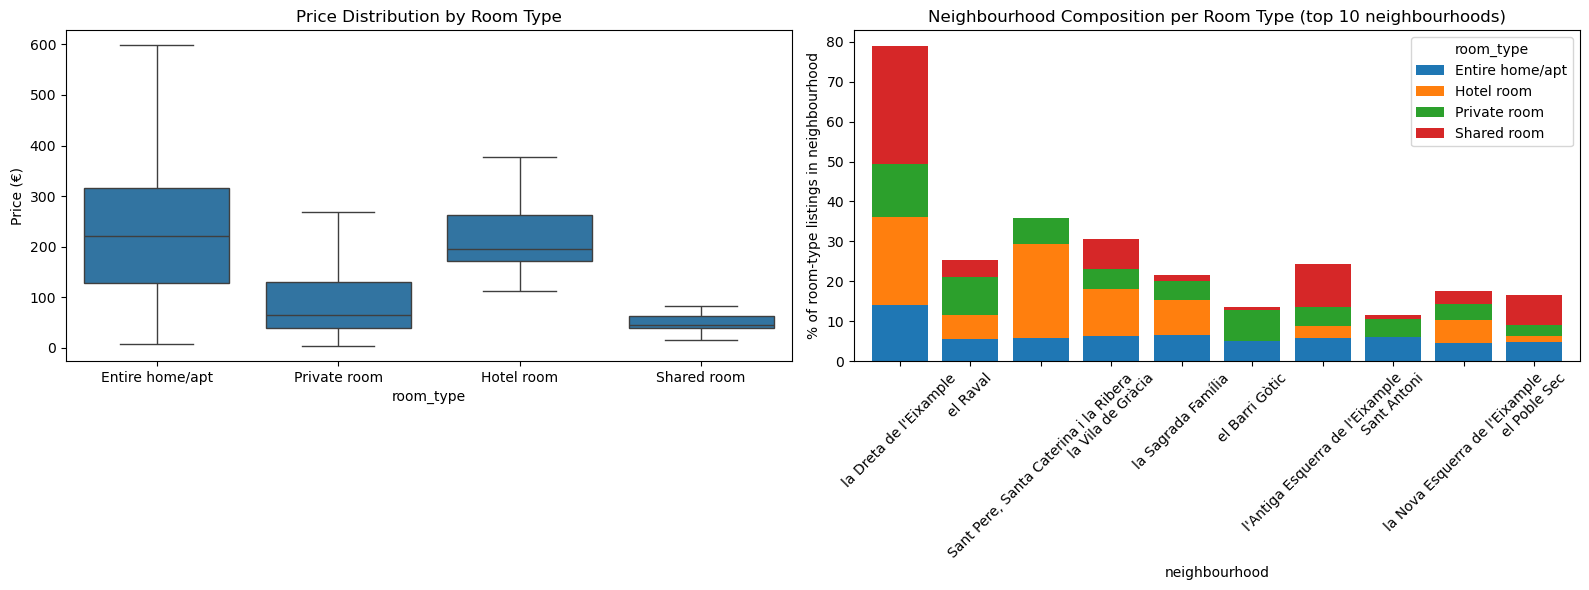

In [6]:
# Neighbourhood distribution per room type
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Price distributions
sns.boxplot(data=listings, x='room_type', y='price', showfliers=False, ax=ax[0])
ax[0].set_title('Price Distribution by Room Type')
ax[0].set_ylabel('Price (€)')

# Neighbourhood share per room type (stacked)
rt_by_nb = pd.crosstab(listings['neighbourhood'], listings['room_type'], normalize='columns').mul(100)
top_nb = listings['neighbourhood'].value_counts().head(10).index
rt_by_nb.loc[top_nb].plot(kind='bar', stacked=True, ax=ax[1], width=0.8)
ax[1].set_title('Neighbourhood Composition per Room Type (top 10 neighbourhoods)')
ax[1].set_ylabel('% of room-type listings in neighbourhood')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()